In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [2]:
# Define transformations for the training and testing sets
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Load the FashionMNIST dataset
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# Define data loaders
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Classes in FashionMNIST
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print(f'Loaded {len(train_dataset)} training samples and {len(test_dataset)} testing samples.')

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 199kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.01MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.96MB/s]

Loaded 60000 training samples and 10000 testing samples.


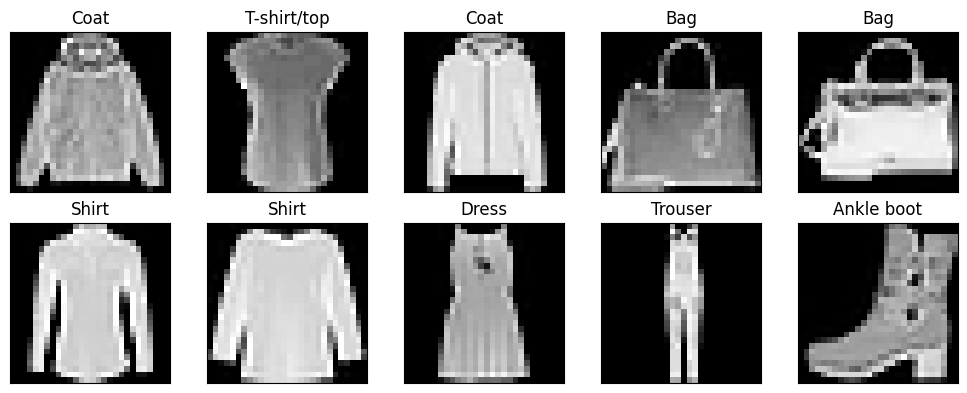

In [3]:
# Visualize a few random training images
dataiter = iter(train_loader)
images, labels = next(dataiter)

fig = plt.figure(figsize=(10, 4))
for idx in range(10):
    ax = fig.add_subplot(2, 5, idx+1, xticks=[], yticks=[])
    # Unnormalize image
    img = images[idx] / 2 + 0.5
    plt.imshow(np.transpose(img.numpy(), (1, 2, 0)).squeeze(), cmap='gray')
    ax.set_title(classes[labels[idx]])

plt.tight_layout()
plt.show()

In [7]:
class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        # Convolutional Block 1
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Convolutional Block 2
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully Connected Layers
        # Input size is 28x28 -> after pool1: 14x14 -> after pool2: 7x7
        self.fc1 = nn.Linear(in_features=64 * 7 * 7, out_features=128)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(in_features=128, out_features=10)

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu1(out)
        out = self.pool1(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu2(out)
        out = self.pool2(out)

        out = out.view(out.size(0), -1) # Flatten
        out = self.fc1(out)
        out = self.relu3(out)
        out = self.dropout(out)
        out = self.fc2(out)
        return out

model = FashionCNN().to(device)
print(model)

FashionCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [8]:
# Define hyperparameters, loss function, and optimizer
num_epochs = 10
learning_rate = 0.001

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Tracking metrics
train_losses = []
train_accs = []

print("Ready to train.")

Ready to train.


In [9]:
# Training Loop
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = (correct / total) * 100

    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc)

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%')

Epoch [1/10], Loss: 0.4371, Accuracy: 84.26%
Epoch [2/10], Loss: 0.3026, Accuracy: 88.93%
Epoch [3/10], Loss: 0.2604, Accuracy: 90.54%
Epoch [4/10], Loss: 0.2365, Accuracy: 91.29%
Epoch [5/10], Loss: 0.2114, Accuracy: 92.16%
Epoch [6/10], Loss: 0.1952, Accuracy: 92.75%
Epoch [7/10], Loss: 0.1800, Accuracy: 93.20%
Epoch [8/10], Loss: 0.1642, Accuracy: 93.85%
Epoch [9/10], Loss: 0.1500, Accuracy: 94.31%
Epoch [10/10], Loss: 0.1417, Accuracy: 94.68%


In [10]:
# Evaluate the model on the test dataset
model.eval()
test_loss = 0.0
correct = 0
total = 0
all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

final_test_loss = test_loss / len(test_loader.dataset)
final_test_acc = (correct / total) * 100
print(f'Test Loss: {final_test_loss:.4f}, Test Accuracy: {final_test_acc:.2f}%')

Test Loss: 0.2484, Test Accuracy: 92.08%


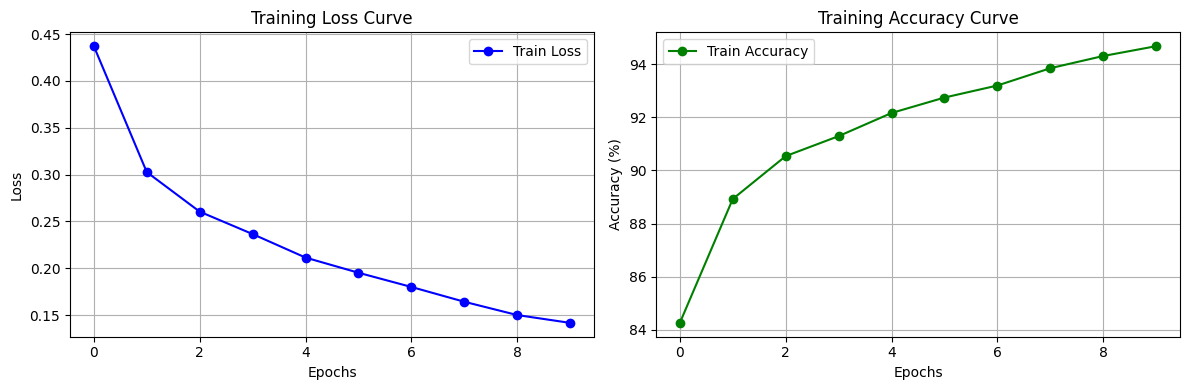

In [11]:
# Plot training loss and accuracy curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, label='Train Loss', color='blue', marker='o')
ax1.set_title('Training Loss Curve')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.grid(True)
ax1.legend()

ax2.plot(train_accs, label='Train Accuracy', color='green', marker='o')
ax2.set_title('Training Accuracy Curve')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.89      0.87      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.84      0.92      0.88      1000
       Dress       0.90      0.95      0.92      1000
        Coat       0.92      0.83      0.87      1000
      Sandal       0.98      0.99      0.99      1000
       Shirt       0.81      0.74      0.77      1000
     Sneaker       0.95      0.98      0.96      1000
         Bag       0.99      0.98      0.99      1000
  Ankle boot       0.99      0.94      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



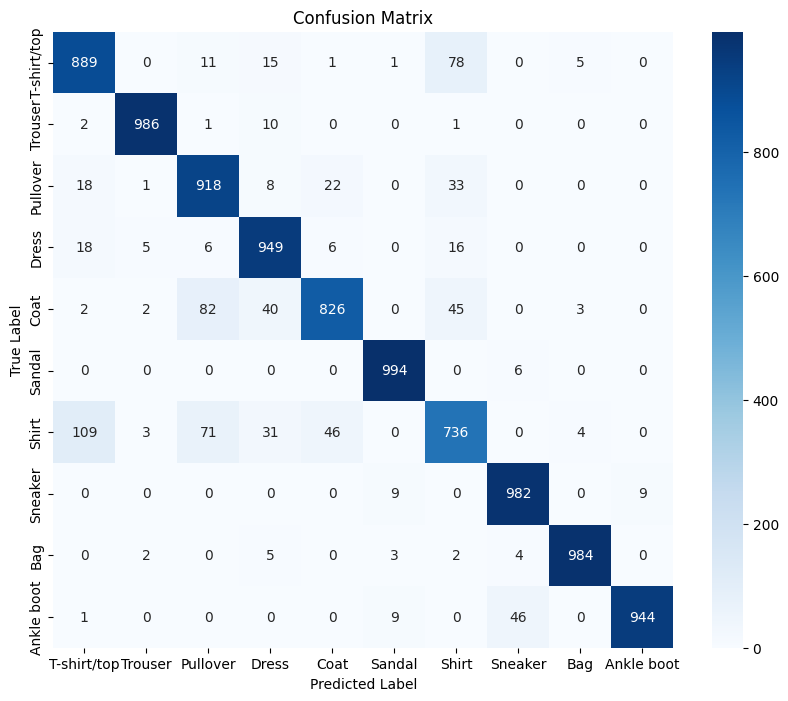

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Generate a classification report and plot confusion matrix
print("Classification Report:")
print(classification_report(all_targets, all_preds, target_names=classes))

cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

Final Summary of Conclusions
CNN Superiority: Implementing a CNN with spatial layer blocks (Convolution, Batch Normalization, and Max Pooling) allows us to capture regional patterns inside 2D clothing structures far more effectively than traditional flat Feedforward Neural Networks (MLPs).
Feature Overlap Challenge: While CNNs are highly capable, they still experience geometric confusion between items with overlapping profiles (like Shirts vs. T-shirts/Pullovers).
Future Recommendations: To further improve classification boundaries on similar apparel, we could introduce Data Augmentation techniques (such as random cropping and horizontal flips) or experiment with deeper network structures.

